# 8. Cosmological constraints from the full shape of the power spectrum

This notebook follows Sec. 4.2 of Paper I.
We forecast what the full-shape multipoles of DESI DR1's six samples constrain, alone and with the BAO ratios of notebook 07 and the BBN prior.
The model is a Kaiser power spectrum of the cold field seen through the Alcock–Paczynski distortion; the covariance is Gaussian.
The machinery is long, so it lives in `_forecast.py` beside this notebook, ported from the paper's figure script; each cell below calls one piece of it and says what it does.
The DESI DR1 posteriors come from the tutorial data bundle.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import time

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from ggah_mod.cosmology import PLANCK18

import _forecast as F

c = PLANCK18
P, ntr = F._FS_P, len(F._FS_Z)
npar = len(P)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The mock measurement

DESI DR1 measures the monopole and quadrupole of six samples (BGS, LRG1, LRG2, LRG3, ELG2, QSO at $z_{\rm eff} = 0.295$–1.491) over $0.02 < k < 0.20\,h\,{\rm Mpc}^{-1}$ in 36 bins of $\Delta k = 0.005$, 432 numbers in all.
Each sample is a Kaiser spectrum of the cold field, $(b_1 + f\mu^2)^2 P_{\rm cb}(k,z)$, with one linear bias per sample and the growth rate $f$ taken on $P_{\rm cb}$.
It is seen through the fiducial distances (Eq. 46):

$$P_\ell(k) = \frac{2\ell+1}{2}\int_{-1}^{1}{\rm d}\mu\,L_\ell(\mu)\frac{(b_1 + f\mu_t^2)^2P_{\rm cb}(k_t)}{\alpha_\perp^2\alpha_\parallel},\qquad
k_t = \frac{ks}{\alpha_\perp},\quad \mu_t = \frac{\mu\alpha_\perp}{\alpha_\parallel s},\quad s^2 = 1 + \mu^2\Big(\frac{\alpha_\perp^2}{\alpha_\parallel^2}-1\Big),$$

with $\alpha_\perp = f_K/f_K^{\rm fid}$ and $\alpha_\parallel = E^{\rm fid}/E$.
Each $b_1$ is set so that the Kaiser monopole at $k = 0.14\,h\,{\rm Mpc}^{-1}$ equals the power DESI quotes there.
`_fs_multipoles(theta, b1)` evaluates the six samples' multipoles, a $\mu$ integral on 24 Gauss–Legendre nodes; `_fs_setup()` builds the fiducial, the Jacobian and the covariance once, and checks them.

In [2]:
fid = F._fs_fid()
t0 = time.perf_counter()
S = F._fs_setup()
print(f"setup: {time.perf_counter() - t0:.1f} s")
for n, z, f, b in zip(F._FS_TRACER, F._FS_Z, fid["f"], S["b0"]):
    print(f"{n:5s} z = {z:5.3f}  f = {f:.4f}  b1 = {b:.3f}")
print(f"quadrature against Kaiser's closed forms at alpha = 1: {S['kaiser_dev']:.0e}")
print(f"d P_l / d ln10A_s against P_l: {S['amp_dev']:.0e}")

setup: 13.4 s
BGS   z = 0.295  f = 0.6811  b1 = 1.616
LRG1  z = 0.510  f = 0.7626  b1 = 1.771
LRG2  z = 0.706  f = 0.8173  b1 = 1.959
LRG3  z = 0.919  f = 0.8610  b1 = 2.107
ELG2  z = 1.317  f = 0.9131  b1 = 1.346
QSO   z = 1.491  f = 0.9279  b1 = 2.022
quadrature against Kaiser's closed forms at alpha = 1: 4e-15
d P_l / d ln10A_s against P_l: 1e-13


At the fiducial $\alpha = 1$ and the quadrature must reproduce Kaiser's closed forms, $P_0 = (b^2 + 2bf/3 + f^2/5)P_{\rm cb}$ and $P_2 = (4bf/3 + 4f^2/7)P_{\rm cb}$; it does to $10^{-15}$.
The amplitude column of the Jacobian equals the model itself, because $f$ is a ratio of two $\sigma_8$ and cannot carry $A_{\rm s}$.

## The covariance

The covariance is that of a Gaussian field in thin $k$ shells, diagonal in $k$, with the two multipoles correlated at each $k$:

$$C_{\ell\ell'}(k) = \frac{(2\ell+1)(2\ell'+1)}{N_k}\int_{-1}^{1}{\rm d}\mu\,L_\ell L_{\ell'}\Big[P_g(k,\mu) + \frac{1}{\bar n}\Big]^2,\qquad N_k = \frac{Vk^2\Delta k}{2\pi^2}.$$

Its normalisation is a volume per sample, set so that the error on the monopole at $k = 2\pi/40 = 0.157\,h\,{\rm Mpc}^{-1}$ is a fraction $\sigma$ of the monopole.
We step $\sigma$ through 0.1, 0.3, 1 and 3 per cent.

In [3]:
cu = F._fs_cov_unit(F._FS_K)
rel = np.sqrt(cu[:, :, 0, 0] / S["vs2"][:, None]) / S["m0"][:, 0]
print("monopole's fractional error at 1%, first and last k bin:")
for n, r in zip(F._FS_TRACER, 100 * 0.01 * rel):
    print(f"  {n:5s} {r[0]:.2f}%  {r[-1]:.2f}%")
np_ = F._FS_P0_014 / F._FS_INV_NBAR
vtrue = F._FS_VEFF * 1e9 * c.h**3 * ((1 + np_) / np_) ** 2
print("DESI DR1's effective volumes correspond to sigma = "
      + ", ".join(f"{100 * x:.1f}%" for x in np.sqrt(S["vs2"] / vtrue)))

monopole's fractional error at 1%, first and last k bin:
  BGS   4.46%  0.93%
  LRG1  4.73%  0.92%
  LRG2  4.56%  0.92%
  LRG3  3.51%  0.98%
  ELG2  2.07%  1.06%
  QSO   1.35%  1.10%
DESI DR1's effective volumes correspond to sigma = 2.8%, 2.2%, 1.8%, 1.7%, 2.4%, 3.3%


## The Fisher matrix

$F_{ij} = \sum_{\rm samples}\sum_k \partial_i\mathbf{P}^{\rm T}C^{-1}\partial_j\mathbf{P}$, in the eight cosmological parameters and the six $b_1$.
With no prior, $F\propto\sigma^{-2}$ and every error scales as $\sigma$.

In [4]:
J = S["J"]
F1 = F._fs_fisher(J, S["cinv1"], S["vs2"], 0.01)
cov_all = {s: np.linalg.inv(F1 * (0.01 / s) ** 2) for s in F._FS_SIG}
cov = {s: v[:npar, :npar] for s, v in cov_all.items()}
print(f"condition number of F (14 parameters): {np.linalg.cond(F1):.0e}   (paper: 3e7)")
for s in F._FS_SIG:
    sd = np.sqrt(np.diag(cov[s]))
    print(f"{100 * s:4g}%  " + "  ".join(f"{p}={x:.3g}" for p, x in zip(P, sd)))
sd1 = np.sqrt(np.diag(cov[0.01]))

condition number of F (14 parameters): 3e+07   (paper: 3e7)
 0.1%  Omega_m=0.000963  Omega_b=0.000322  h=0.00322  n_s=0.00321  ln10A_s=0.0122  w0=0.00585  wa=0.0322  Omega_k=0.00291
 0.3%  Omega_m=0.00289  Omega_b=0.000965  h=0.00965  n_s=0.00964  ln10A_s=0.0365  w0=0.0175  wa=0.0965  Omega_k=0.00873
   1%  Omega_m=0.00963  Omega_b=0.00322  h=0.0322  n_s=0.0321  ln10A_s=0.122  w0=0.0585  wa=0.322  Omega_k=0.0291
   3%  Omega_m=0.0289  Omega_b=0.00965  h=0.0965  n_s=0.0964  ln10A_s=0.365  w0=0.175  wa=0.965  Omega_k=0.0873


The quadrupole is what measures the amplitude: from the monopole alone $b_1$ and $A_{\rm s}$ are degenerate.

In [5]:
Fm = 0.0
for i in range(ntr):
    var0 = cu[i, :, 0, 0] * 0.01**2 / S["vs2"][i]
    Fm = Fm + J[i, 0].T @ (J[i, 0] / var0[:, None])
print(f"monopole alone: condition number {np.linalg.cond(Fm):.0e}")
sd_all = np.sqrt(np.diag(cov_all[0.01]))
corr = cov_all[0.01] / np.outer(sd_all, sd_all)
ia, ih, ins = P.index("ln10A_s"), P.index("h"), P.index("n_s")
print("corr(b1, ln10A_s) = " + " ".join(f"{corr[npar + i, ia]:+.2f}" for i in range(ntr)))
print(f"corr(h, n_s) = {corr[ih, ins]:+.2f},  corr(h, ln10A_s) = {corr[ih, ia]:+.2f}")
c2 = cov[0.01][np.ix_([5, 6], [5, 6])]
z_p = 1 / (1 + c2[0, 1] / c2[1, 1]) - 1
print(f"w0-wa pivot: z_p = {z_p:.2f}   (BAO ratios: 0.27)")

monopole alone: condition number 3e+18
corr(b1, ln10A_s) = -0.76 -0.76 -0.79 -0.81 -0.83 -0.85
corr(h, n_s) = -0.96,  corr(h, ln10A_s) = -0.95
w0-wa pivot: z_p = 0.19   (BAO ratios: 0.27)


## On DESI's footing

DESI DR1's full-shape result is in flat $\Lambda$CDM with the BBN prior and $n_{\rm s} = 0.9649\pm0.042$.
We put the forecast on that footing and find the precision at which it has DESI's errors.
DESI's model carries seven nuisance parameters per sample, against $b_1$ alone here, so a given precision constrains more here than in DESI's analysis.

In [6]:
PN = P + tuple(f"b_{n}" for n in F._FS_TRACER)
g8 = F._fs_sigma8_gradient(S["t0"])


def prior_bbn_ns():
    Fp = np.zeros((npar + ntr, npar + ntr))
    Fp += F._bbn_prior(S["T0"], PN)
    Fp[ins, ins] += 1.0 / F._NS10[1] ** 2
    return Fp


err = F._fs_lcdm(S, F1, prior_bbn_ns, g8)
e1 = err(0.01)
print("flat LCDM at 1%: " + "  ".join(f"{p}={e1[p]:.2g}" for p in ("Omega_m", "H0", "sigma8", "ln10A_s", "n_s")))
DF = F.DF
lim = {p: DF.limits68("fs", p) for p in ("Omega_m", "H0", "sigma8", "ln10A_s", "n_s")}
print("DESI DR1 FS:     " + "  ".join(f"{p}={m[1]:.2g}" for p, m in lim.items()))
match = {p: F._fs_match(lambda s, _p=p: err(s)[_p], lim[p][1]) for p in lim}
print("precision at which the forecast has DESI's error: "
      + "  ".join(f"{p} {100 * x:.1f}%" for p, x in match.items()))

flat LCDM at 1%: Omega_m=0.0029  H0=0.52  sigma8=0.0025  ln10A_s=0.016  n_s=0.0071
DESI DR1 FS:     Omega_m=0.011  H0=1  sigma8=0.034  ln10A_s=0.1  n_s=0.029
precision at which the forecast has DESI's error: Omega_m 4.2%  H0 4.2%  sigma8 13.5%  ln10A_s 10.6%  n_s 6.5%


## Is the Fisher matrix the likelihood?

As in notebook 07, we step $\pm1\sigma$ along each principal direction of the eight cosmological parameters' covariance and evaluate the exact $\chi^2$.
The six $b_1$ are profiled there, as they are marginalised in $F^{-1}$; each multipole is quadratic in its $b_1$, so the profile is the root of a cubic.
A point outside the emulator's training box is refused.

In [7]:
chi2max, refused_at = F._fs_validity(cov, F._FS_SIG, lambda t, s: F._fs_chi2_profiled(t, s, S)[0],
                                     P, S["t0"], "full shape alone")
SIG_ALONE = F._FS_SIG_ALONE
invalid = {s for s in SIG_ALONE if chi2max[s] > 2.0 or refused_at[s] > 0}

  exact chi^2 (full shape alone), b1 profiled, at the +-1 sigma points along the principal directions (Fisher: 1):


      0.1%  min 0.997  max 1.033  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.000727, Omega_b -0.000191, h -0.000957, n_s +0.00146, ln10A_s +0.00221, w0 -0.00519, wa +0.0321, Omega_k -0.00199)


      0.3%  min 0.990  max 1.245  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.00218, Omega_b -0.000574, h -0.00287, n_s +0.00438, ln10A_s +0.00662, w0 -0.0156, wa +0.0964, Omega_k -0.00598)


        1%  min 0.966  max 4.222  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.00727, Omega_b -0.00191, h -0.00957, n_s +0.0146, ln10A_s +0.0221, w0 -0.0519, wa +0.321, Omega_k -0.0199)


      refused at 3%, step in marginal sigma: Omega_m -0.47, Omega_b -0.71, h -0.91, n_s +0.87, ln10A_s +0.98, w0 -0.20, wa -0.03, Omega_k +0.65 -- outside the emulator training box, where the network extrapolates with no accuracy guarantee: omega_b = 0.014573 not in [0.017, 0.028].
      refused at 3%, step in marginal sigma: Omega_m +0.47, Omega_b +0.71, h +0.91, n_s -0.87, ln10A_s -0.98, w0 +0.20, wa +0.03, Omega_k -0.65 -- outside the emulator training box, where the network extrapolates with no accuracy guarantee: omega_b = 0.032541 not in [0.017, 0.028].
      refused at 3%, step in marginal sigma: Omega_m -0.76, Omega_b -0.60, h -0.30, n_s +0.45, ln10A_s +0.18, w0 -0.89, wa +1.00, Omega_k -0.69 -- outside the emulator training box, where the network extrapolates with no accuracy guarantee: wa = 0.96428 not in [-1, 0.6].
        3%  min 0.899  max 9.471  (3 of 16 points outside the box; max at the - end of the step Omega_m +0.0218, Omega_b +0.00574, h +0.0287, n_s -0.0438, ln10A_s

## Figure: the full shape alone

Fig. 10 of the paper, at 0.1, 0.3 and 1 per cent; the 3 per cent forecast leaves the emulator's box and is not drawn.
The purple outlines are DESI DR1's own full-shape posterior in flat $\Lambda$CDM with the BBN and $n_{\rm s}$ priors.

  axes: Omega_m [0.2661, 0.3317]  Omega_b [0.04286, 0.05477]  h [0.6189, 0.7283]  n_s [0.9103, 1.051]  ln10A_s [2.837, 3.266]  w0 [-1.099, -0.9006]  wa [-0.5468, 0.5468]  Omega_k [-0.04945, 0.04945]


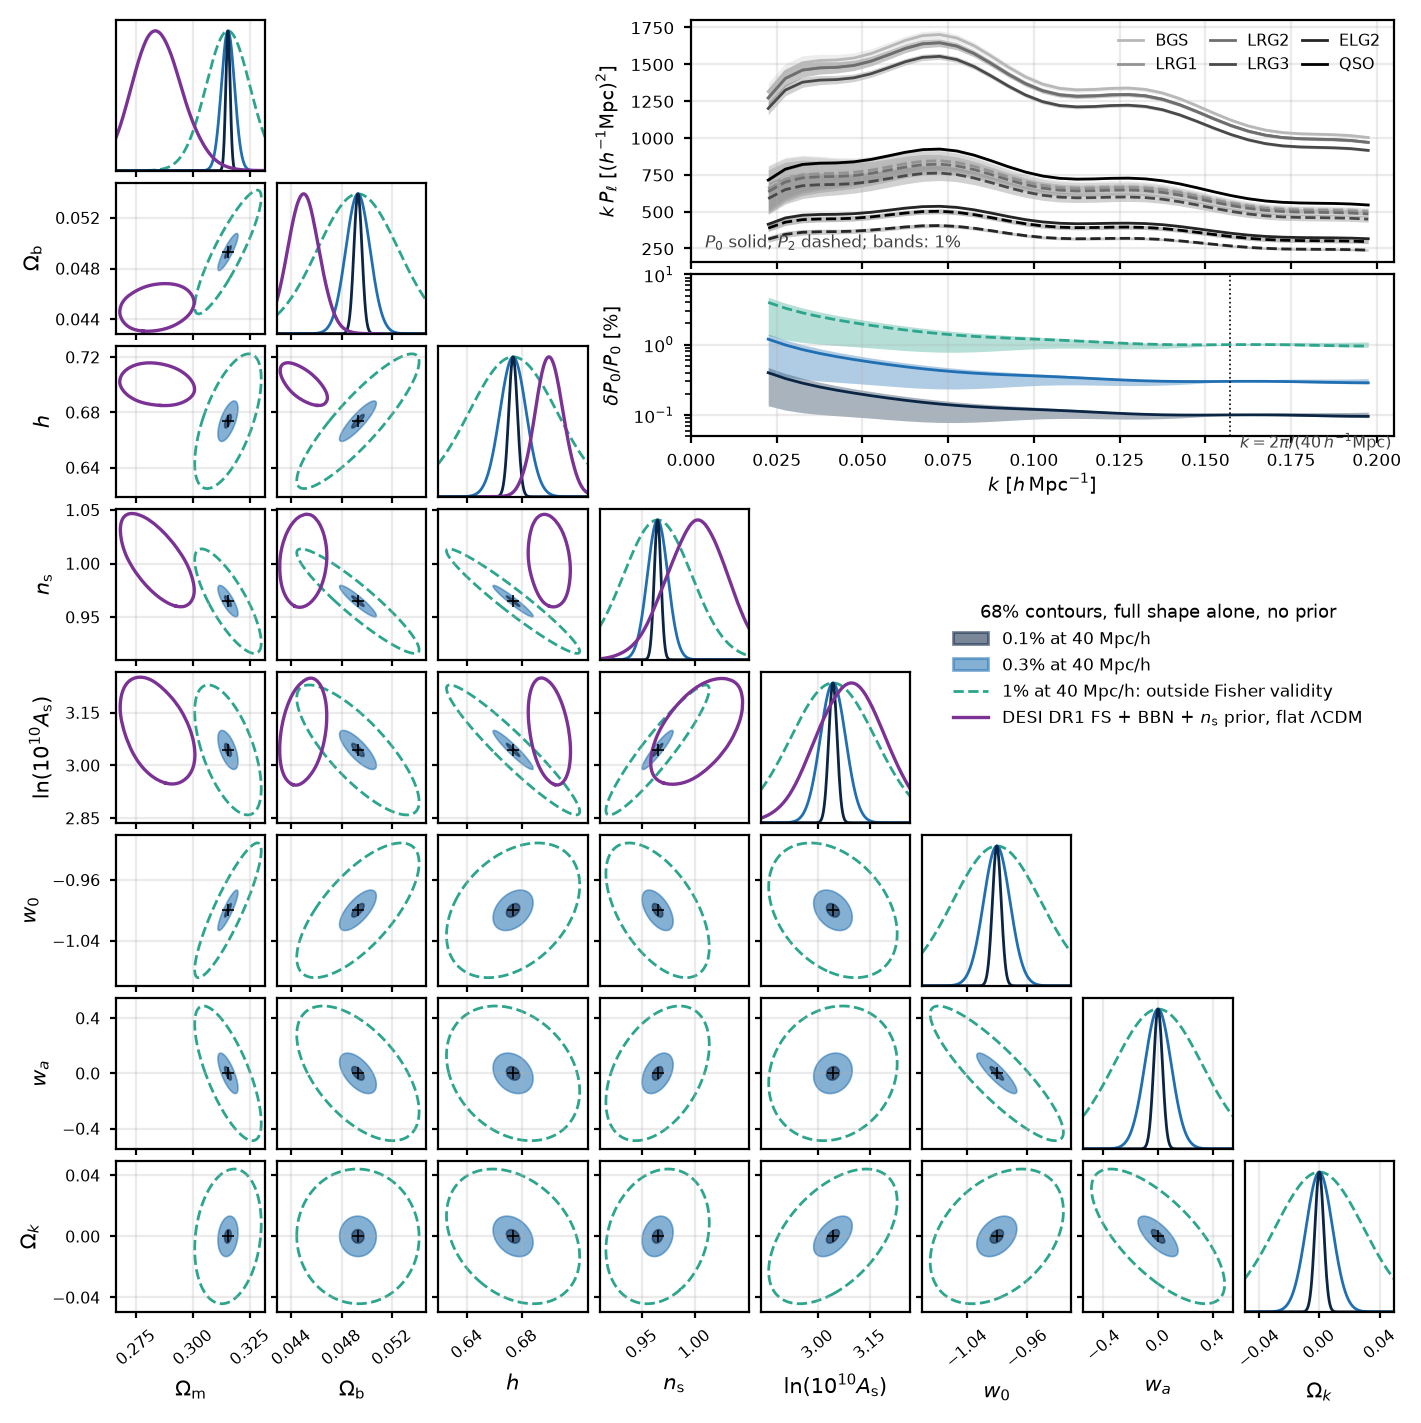

In [8]:
t0v, m0 = S["t0"], S["m0"]
fig = plt.figure(figsize=(7.1, 7.1))
gs = fig.add_gridspec(npar, npar, hspace=0.08, wspace=0.08, left=0.085, right=0.985, bottom=0.075, top=0.985)
lims = F._fs_lims(t0v, cov[F._FS_FRAME["fs"]], P, "fs")
F._fisher_corner(fig, gs, P, t0v, cov, SIG_ALONE, F._FS_COLOUR, invalid, lims, chain="fs")

sub = gs[0:3, 3:8].subgridspec(3, 2, height_ratios=(1.5, 1.0, 0.30), width_ratios=(0.13, 1.0), hspace=0.08, wspace=0.0)
am, ae = fig.add_subplot(sub[0, 1]), fig.add_subplot(sub[1, 1])
K = F._FS_K
for a in (am, ae):
    a.tick_params(labelsize=6.2, length=2.5)
    a.set_xlim(0.0, 0.205)
grey = np.linspace(0.72, 0.0, ntr)
for i, n in enumerate(F._FS_TRACER):
    e = np.sqrt(np.stack([cu[i, :, 0, 0], cu[i, :, 1, 1]]) / S["vs2"][i]) * 0.01
    for ell, ls in ((0, "-"), (1, "--")):
        y = K * m0[i, ell]
        am.fill_between(K, y - K * e[ell], y + K * e[ell], color=str(grey[i]), alpha=0.25, lw=0)
        am.plot(K, y, color=str(grey[i]), lw=1.0, ls=ls, label=n if ell == 0 else None)
am.set_ylabel(r"$k\,P_\ell$ [$(h^{-1}{\rm Mpc})^2$]", fontsize=7)
am.tick_params(labelbottom=False)
am.legend(fontsize=5.6, ncol=3, loc="upper right", frameon=False, handlelength=1.6, columnspacing=0.8)
am.text(0.02, 0.06, r"$P_0$ solid, $P_2$ dashed; bands: 1%", transform=am.transAxes, fontsize=6.0, color="0.25")
for s, col in zip(SIG_ALONE, F._FS_COLOUR):
    r = 100 * rel * s
    ae.fill_between(K, r.min(0), r.max(0), color=col, alpha=0.35, lw=0)
    ae.plot(K, np.median(r, 0), color=col, lw=1.0, ls="--" if s in invalid else "-")
ae.axvline(F._FS_K40, color="k", lw=0.6, ls=":")
ae.text(F._FS_K40 + 0.003, 0.03, r"$k = 2\pi/(40\,h^{-1}{\rm Mpc})$", fontsize=5.8, color="0.25", va="bottom")
ae.set_yscale("log")
ae.set_ylim(0.05, 10.0)
ae.set_xlabel(r"$k$ [$h\,{\rm Mpc}^{-1}$]", fontsize=7, labelpad=1)
ae.set_ylabel(r"$\delta P_0/P_0$ [%]", fontsize=7)

al = fig.add_subplot(gs[3:5, 5:8])
al.axis("off")
hand = [Line2D([], [], color=col, ls="--", lw=1.0) if s in invalid else Patch(fc=col, ec=col, alpha=0.55)
        for s, col in zip(SIG_ALONE, F._FS_COLOUR)]
labs = [f"{100 * s:g}% at 40 Mpc/h" + (": outside Fisher validity" if s in invalid else "") for s in SIG_ALONE]
hand.append(Line2D([], [], **F._FS_DESI_STYLE))
labs.append(F._FS_DESI_LABEL["fs"])
al.legend(hand, labs, loc="center", fontsize=6.3, frameon=False,
          title="68% contours, full shape alone, no prior", title_fontsize=6.6);
T.save_figure(fig, "fig_pk_fisher")

## Adding the BAO ratios and the BBN prior

We add the thirteen BAO ratios of notebook 07 at 1 per cent and the BBN prior, as an independent Fisher matrix.
That counts the acoustic feature the multipoles contain twice; DESI fits the two with a joint covariance.

In [9]:
ib = [P.index(p) for p in F._BAO_P]
z, tb0 = F._BAO_Z, t0v[ib]
d0 = np.asarray(F._ln_bao(jnp.asarray(tb0), z))
M, _ = F._bao_observed()
Jb = M @ np.asarray(jax.jacfwd(lambda t: F._ln_bao(t, z))(jnp.asarray(tb0)))
Fb6 = Jb.T @ Jb / F._FS_BAO_SIG**2 + F._bbn_prior(tb0)
cov_bao = np.linalg.inv(Fb6)
Fb = np.zeros((npar + ntr, npar + ntr))
Fb[np.ix_(ib, ib)] = Fb6


def cov_comb(s):
    return np.linalg.inv(F1 * (0.01 / s) ** 2 + Fb)[:npar, :npar]


def cov_fs(s):
    return np.linalg.inv(F1 * (0.01 / s) ** 2)[:npar, :npar]


covc = {s: cov_comb(s) for s in F._FS_SIG}
sdb = np.sqrt(np.diag(cov_bao))
sdc1 = np.sqrt(np.diag(covc[0.01]))
print("BAO + BBN alone:     " + "  ".join(f"{p}={x:.2g}" for p, x in zip(F._BAO_P, sdb)))
print("with full shape 1%:  " + "  ".join(f"{p}={sdc1[P.index(p)]:.2g}" for p in F._BAO_P))

wb0 = t0v[P.index("Omega_b")] * t0v[ih] ** 2


def chi2_comb(t, s):
    x = F._fs_chi2_profiled(t, s, S)[0]
    r = M @ (np.asarray(F._ln_bao(jnp.asarray(t[ib]), z)) - d0)
    wb = t[P.index("Omega_b")] * t[ih] ** 2
    return x + float(r @ r) / F._FS_BAO_SIG**2 + ((wb - wb0) / F._BBN_OMEGA_B[1]) ** 2


chi2c, refc = F._fs_validity(covc, F._FS_SIG, chi2_comb, P, t0v, "full shape + BAO + BBN")
invalid_c = {s for s in F._FS_SIG if chi2c[s] > 2.0 or refc[s] > 0}

BAO + BBN alone:     Omega_m=0.044  Omega_b=0.0029  h=0.02  w0=0.26  wa=1.2  Omega_k=0.034
with full shape 1%:  Omega_m=0.0056  Omega_b=0.00092  h=0.0072  w0=0.045  wa=0.24  Omega_k=0.021
  exact chi^2 (full shape + BAO + BBN), b1 profiled, at the +-1 sigma points along the principal directions (Fisher: 1):


      0.1%  min 0.997  max 1.032  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.000647, Omega_b -0.000154, h -0.000543, n_s +0.00106, ln10A_s +0.000702, w0 -0.00492, wa +0.0313, Omega_k -0.00214)


      0.3%  min 0.986  max 1.206  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.00151, Omega_b -0.000272, h +0.000392, n_s +0.00122, ln10A_s -0.00496, w0 -0.0132, wa +0.0878, Omega_k -0.00687)


        1%  min 0.981  max 1.864  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.00387, Omega_b -0.000536, h +0.00287, n_s +0.00203, ln10A_s -0.0139, w0 -0.0378, wa +0.235, Omega_k -0.0169)


        3%  min 0.988  max 1.872  (0 of 16 points outside the box; max at the + end of the step Omega_m -0.00948, Omega_b -0.000877, h +0.00542, n_s +0.00894, ln10A_s +0.011, w0 -0.0894, wa +0.432, Omega_k -0.0176)


Fig. 11 of the paper: with the ratios, the ellipses are the forecast at all four precisions.
Upper right: each combined error as a fraction of the full shape's alone (top) and of BAO and BBN alone (bottom).

  axes: Omega_m [0.2803, 0.3368]  Omega_b [0.04516, 0.05214]  h [0.6535, 0.6983]  n_s [0.9287, 1.04]  ln10A_s [2.906, 3.27]  w0 [-1.176, -0.8241]  wa [-0.7341, 0.7341]  Omega_k [-0.05063, 0.05063]


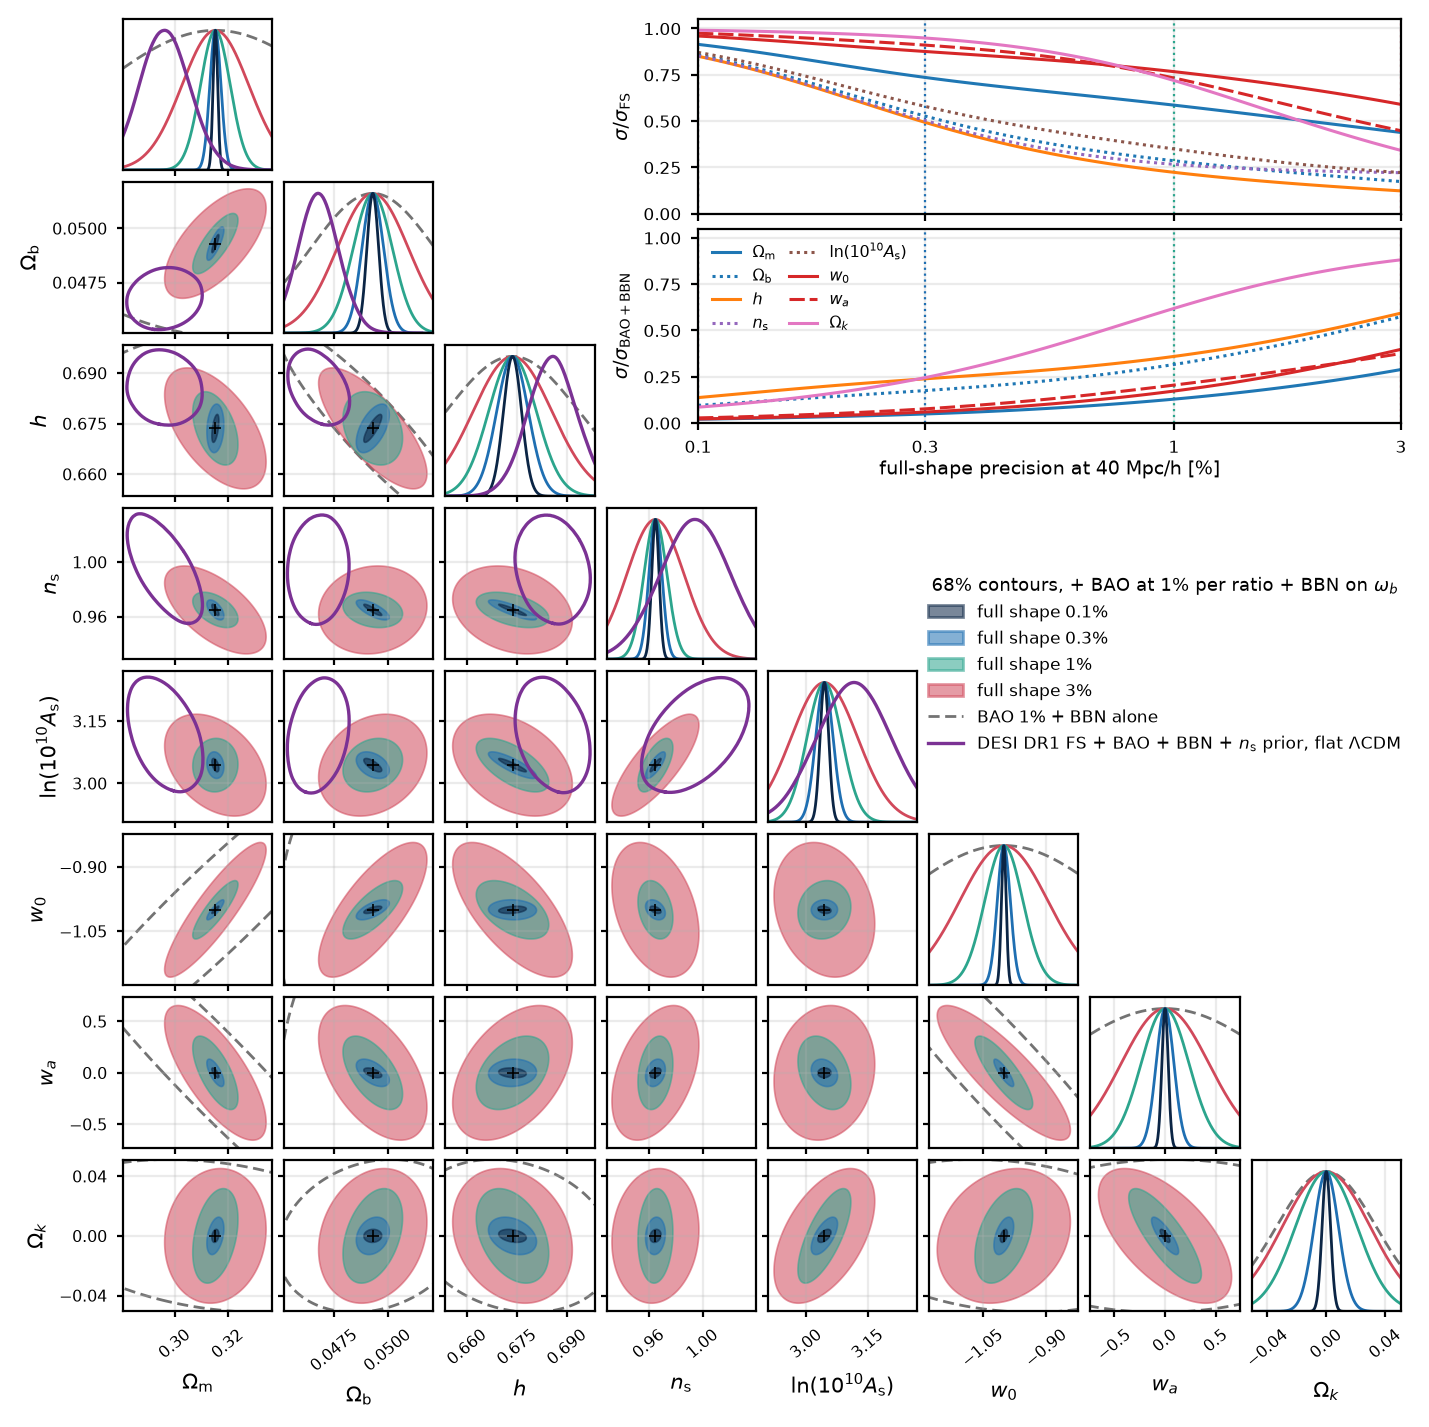

In [10]:
fig = plt.figure(figsize=(7.1, 7.1))
gs = fig.add_gridspec(npar, npar, hspace=0.08, wspace=0.08, left=0.085, right=0.985, bottom=0.075, top=0.985)
lims = F._fs_lims(t0v, covc[F._FS_FRAME["fsbao"]], P, "fsbao")
ref_style = dict(color="0.45", lw=1.0, ls=(0, (4, 2)))
F._fisher_corner(fig, gs, P, t0v, covc, F._FS_SIG, F._FS_COLOUR, invalid_c, lims, chain="fsbao",
                 ref=(cov_bao, F._BAO_P, ref_style))
sub = gs[0:3, 3:8].subgridspec(3, 2, height_ratios=(1.0, 1.0, 0.30), width_ratios=(0.13, 1.0), hspace=0.10, wspace=0.0)
ar, ab = fig.add_subplot(sub[0, 1]), fig.add_subplot(sub[1, 1])
g = np.geomspace(F._FS_SIG[0], F._FS_SIG[-1], 40 if FAST else 120)
sdc = np.array([np.sqrt(np.diag(cov_comb(s))) for s in g])
sdf = np.array([np.sqrt(np.diag(cov_fs(s))) for s in g])
for a in (ar, ab):
    a.tick_params(labelsize=6.2, length=2.5)
    a.set_xscale("log")
    a.set_xlim(100 * F._FS_SIG[0], 100 * F._FS_SIG[-1])
    a.set_ylim(0.0, 1.05)
    a.set_xticks([0.1, 0.3, 1.0, 3.0])
    a.set_xticks([], minor=True)
    a.set_xticklabels(["0.1", "0.3", "1", "3"])
    for s, col in zip(F._FS_SIG, F._FS_COLOUR):
        a.axvline(100 * s, color=col, lw=0.8, ls=":")
for i, p in enumerate(P):
    colour, ls = T.DSTYLE[p]
    ar.plot(100 * g, sdc[:, i] / sdf[:, i], color=colour, ls=ls, lw=1.1, label=T.TEX[p])
    if p in F._BAO_P:
        ab.plot(100 * g, sdc[:, i] / sdb[F._BAO_P.index(p)], color=colour, ls=ls, lw=1.1)
ar.set_ylabel(r"$\sigma/\sigma_{\rm FS}$", fontsize=7)
ab.set_ylabel(r"$\sigma/\sigma_{\rm BAO+BBN}$", fontsize=7)
ar.tick_params(labelbottom=False)
ab.set_xlabel("full-shape precision at 40 Mpc/h [%]", fontsize=7, labelpad=1)
ab.legend(*ar.get_legend_handles_labels(), fontsize=5.6, ncol=2, loc="upper left", frameon=False,
          handlelength=1.8, columnspacing=0.8)
al = fig.add_subplot(gs[3:5, 5:8])
al.axis("off")
hand = [Line2D([], [], color=col, ls="--", lw=1.0) if s in invalid_c else Patch(fc=col, ec=col, alpha=0.55)
        for s, col in zip(F._FS_SIG, F._FS_COLOUR)]
labs = [f"full shape {100 * s:g}%" for s in F._FS_SIG]
hand += [Line2D([], [], **ref_style), Line2D([], [], **F._FS_DESI_STYLE)]
labs += ["BAO 1% + BBN alone", F._FS_DESI_LABEL["fsbao"]]
al.legend(hand, labs, loc="center", fontsize=6.3, frameon=False,
          title=r"68% contours, + BAO at 1% per ratio + BBN on $\omega_b$", title_fontsize=6.6);
T.save_figure(fig, "fig_pk_bao_fisher")

## Exercises

1. Free $\sum m_\nu$ at 1 per cent (extend `P` and rebuild the Jacobian with `F._fs_multipoles(T[:ne], T[ne:], P + ("sum_mnu",))`). What is $\sigma(\sum m_\nu)$, and how much does $\sigma(\Omega_{\rm m})$ grow?
2. Replace $P_{\rm cb}$ by its no-wiggle version (`nowiggle=True` in `F._fs_basis`) and redo the combined forecast. How much of the gain from the BAO ratios was the acoustic feature counted twice?
3. Add two counterterms per sample, $-2k^2(\alpha_0 + \alpha_2\mu^2)P_{\rm cb}$, as free parameters. By how much do the 1 per cent errors grow?

Next: notebook 09, cosmological constraints from the halo mass function.